# Master file for Laboration 1

## Load all packages

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import random

## Action matrices

### Local action matrix
TODO!!

In [26]:
# Task 1 when only changing price 
def local_action_matrix_1D_price(x,p):
    actions = np.array([
        [x, p + dp_change]
        for dp_change in [-dp, 0, dp]
    ])

    # Make sure values are within boundaries.
    actions[:, 1] = np.clip(actions[:, 1], 0, p_max)   # price

    return actions

In [27]:
# Task 1 when only changing position.
def local_action_matrix_1D_pos(x,p):
    actions = np.array([
        [x + dx_change, p]
        for dx_change in [-dx, 0, dx]
    ])

    # Make sure values are within boundaries.
    actions[:, 0] = np.clip(actions[:, 0], -1, 1)   # price

    return actions

In [28]:
def local_action_matrix_1D(x, p):

    actions = np.array([
        [x + dx_change, p + dp_change]

        for dx_change in [-dx, 0, dx]
        for dp_change in [-dp, 0, dp]
    ])

    # Make sure values are within boundaries.
    actions[:, 0] = np.clip(actions[:, 0], -1, 1)      # x
    actions[:, 1] = np.clip(actions[:, 1], 0, p_max)   # price

    return actions

In [29]:
def local_action_matrix_2D(z, p):
    x,y = z[0], z[1] 

    actions = np.array([
        [x + dx_change, y + dy_change, p + dp_change]

        for dx_change in [-dx, 0, dx]
        for dy_change in [-dy, 0, dy]
        for dp_change in [-dp, 0, dp]
    ])

    # Make sure values are within boundaries.
    actions[:, 0] = np.clip(actions[:, 0], -1, 1)      # x
    actions[:, 1] = np.clip(actions[:, 1], -1, 1)      # y
    actions[:, 2] = np.clip(actions[:, 2], 0, p_max)   # price

    return actions

### Global action matrix

In [30]:
# The input are dummy variables, it acts like a constant function
def global_action_matrix(z,p):
    return np.array([
        [x, p]
        for x in road
        for p in prices
    ])
#print("Action matrix shape:", global_action_matrix.shape)

## Important functions

In [31]:
def distances_2d(z,plane):
    x,y = z[0],z[1]
    distances = np.sqrt(
    (plane[:, 0] - x)**2 +
    (plane[:, 1] - y)**2)
    return distances


In [32]:
def calculate_profit(x, p, costfunc, k, c0, demfunc, e):

    costs = [None]*len(x)
    for i in range(len(x)):
        costs[i] = costfunc(x[i], p[i], k)

    costs = np.array(costs)
    # Customers choose cheapest firm, splitting ties equally
    # min_cost = np.min(costs, axis=0)
    # ties = (costs == min_cost)
    # customers = ties / np.sum(ties, axis=0)

    min_cost = np.min(costs, axis=0)
    ties = np.isclose(costs, min_cost)
    customers = ties / np.sum(ties, axis=0)

    # Quantity sold
    Q = [None]*len(x)

    for i in range(len(x)):
        Q[i] = customers[i] * demfunc(costs[i], e)

    # Profit of each firm
    profit = [None]*len(x)

    for i in range(len(x)):
        profit[i] = (p[i] - c0) * np.sum(Q[i])

    return profit

In [33]:
def best_move(x, p, firm, action_matrix, costfunc, k, c0, demfunc, e):

    best_profit = -np.inf
    x_best = None
    p_best = None

    actionmatrix = action_matrix(x[firm], p[firm])

    for action in actionmatrix:

        pos = action[:-1] #allindeces but the last, solves 1d or 2d
        price = action[-1] #last index

        if x.ndim == 1:
            pos = pos[0]

        x_new = x.copy()
        p_new = p.copy()

        x_new[firm] = pos
        p_new[firm] = price

        profit = calculate_profit(
            x_new, p_new, costfunc, k, c0, demfunc, e
        )

        if profit[firm] > best_profit:
            best_profit = profit[firm]
            x_best = pos
            p_best = price

    return x_best, p_best

In [34]:
# GPT wrote this to avoid 200 000 000 iterations :)))))
def best_move_global(x1, x2, p1, p2, firm, action_matrix, k,c0,demfunc,e):

    # All possible actions
    x = action_matrix[:, 0]
    p = action_matrix[:, 1]

    # Each row = one possible action
    # Each column = one customer
    if firm == 1:
        cost1 = p[:, None] + k * np.abs(x[:, None] - road[None, :])
        cost2 = p2 + k * np.abs(x2 - road)

        customers = np.sum(cost1 < cost2, axis=1)
        ties = np.sum(np.isclose(cost1, cost2), axis=1)

    else:
        cost1 = p1 + k * np.abs(x1 - road)
        cost2 = p[:, None] + k * np.abs(x[:, None] - road[None, :])

        customers = np.sum(cost2 < cost1, axis=1)
        ties = np.sum(np.isclose(cost1, cost2), axis=1)

    # Half of tied customers go to each firm
    Q = (customers + 0.5 * ties) * D / len(road)

    # Profit for every possible action
    profits = (p - c0) * Q

    # Index of highest profit
    best = np.argmax(profits)

    return x[best], p[best]

In [35]:
def detect_cycle(x, p, seen_states, iteration):

    state = (
        tuple(np.asarray(x).flatten()),
        tuple(np.round(np.asarray(p), 6))
    )

    if state in seen_states:
        first_iteration = seen_states[state]
        cycle_length = iteration - first_iteration

        return True, first_iteration, cycle_length

    seen_states[state] = iteration

    return False, None, None

In [36]:
def equilibrium(x, p, action_matrix, costfunc, k, c0, demfunc, e):

    # Trajectories
    history_x = [x.copy()]
    history_p = [p.copy()]

    profit = calculate_profit(x, p, costfunc, k, c0, demfunc, e)
    history_profit = [profit.copy()]

    # Cycle detection
    seen_states = {}
    first_iteration = None
    cycle_length = None
    stop_reason = "1000 iterations"

    for iteration in range(1000):

        # Cycle detection
        cycle, first_iteration_cycle, cycle_length_cycle = detect_cycle(
            x, p, seen_states, iteration
        )

        if cycle:
            first_iteration = first_iteration_cycle
            cycle_length = cycle_length_cycle
            stop_reason = "Cycle"
            break

        # Save old state
        old_x = x.copy()
        old_p = p.copy()

        # Every firm takes a turn
        for firm in range(len(x)):

            x[firm], p[firm] = best_move(
                x, p, firm,
                action_matrix,
                costfunc, k, c0, demfunc, e
            )

        # Calculate profits after all firms have taken their turn
        profit = calculate_profit(
            x, p, costfunc, k, c0, demfunc, e
        )

        # Save trajectories
        history_x.append(x.copy())
        history_p.append(p.copy())
        history_profit.append(profit.copy())

        # No changes in price or position -> convergence
        if (
            np.array_equal(x, old_x)
            and np.array_equal(p, old_p)
        ):
            stop_reason = "Convergence"
            break

    return (
        x, p,
        history_x, history_p, history_profit,
        stop_reason, first_iteration, cycle_length
    )

In [37]:
# Main
# Model parameters

k = 1.0                  # Travel cost

# Price parameters
p_max = 4
dp = 0.1
n = 101                  # Number of customers and possible positions
D = 1.0                  # Total demand

# Possible prices
prices = np.arange(0, p_max + dp/2, dp)
e=0.5                    # Elasticity for elastic demand

# Cost of pizza
c0 = 1

# Possible 1D locations
road = np.linspace(-1, 1, n)

dx=2/(n-1)
dy=2/(n-1)

# Possible 2d locations
x_values = np.linspace(-1, 1, n)
y_values = np.linspace(-1, 1, n)
plane = np.array([
    [x, y]
    for x in x_values
    for y in y_values
])


def costfunc1D(x, p, k):
    return p+k*np.abs(road - x)

def costfunc2D(z,p,k):
    return p+k*distances_2d(z,plane)

def demandfunc1(tc,e):
    return D/n

def demandfunc2(tc,e):
        return np.maximum(0.0,(D/n)*(1-e*tc))
    


# DIFFERENT STARTING VALUES FOR ALL TASKS
# DIFFERENT STARTING VALUES FOR ALL TASKS

# Task 1
x_1 = np.random.choice(road, 2)
p_1 = np.array([1.0, 1.0])

# Task 3
x_3 = np.random.choice(road, 2)
p_3 = np.random.choice(prices, 2)

# Task 4
x_4 = np.random.choice(road, 2)
p_4 = np.random.choice(prices, 2)

# Task 5
x_5 = np.random.choice(road, 2)
p_5 = np.random.choice(prices, 2)

# Task 6
m = 2

x_6 = np.random.choice(road, size=(m, 2))
p_6 = np.random.choice(prices, size=m)



# Task 1
(
    x_1, p_1,
    history_x_1, history_p_1, history_profit_1,
    stop_reason_1, first_iteration_1, cycle_length_1
) = equilibrium(
    x_1, p_1,
    local_action_matrix_1D_pos,
    costfunc1D, k, 0, demandfunc1, e
)

# Task 3
(
    x_3, p_3,
    history_x_3, history_p_3, history_profit_3,
    stop_reason_3, first_iteration_3, cycle_length_3
) = equilibrium(
    x_3, p_3,
    local_action_matrix_1D,
    costfunc1D, k, c0, demandfunc1, e
)

#Task 4
(
    x_4, p_4,
    history_x_4, history_p_4, history_profit_4,
    stop_reason_4, first_iteration_4, cycle_length_4
) = equilibrium(
    x_4, p_4,
    global_action_matrix,
    costfunc1D, k, c0, demandfunc1, e
)

# Task 5
(
    x_5, p_5,
    history_x_5, history_p_5, history_profit_5,
    stop_reason_5, first_iteration_5, cycle_length_5
) = equilibrium(
    x_5, p_5,
    local_action_matrix_1D,
    costfunc1D, k, c0, demandfunc2, e
)

# Task 6
(
    x_6, p_6,
    history_x_6, history_p_6, history_profit_6,
    stop_reason_6, first_iteration_6, cycle_length_6
) = equilibrium(
    x_6, p_6,
    local_action_matrix_2D,
    costfunc2D, k, c0, demandfunc1, e
)

In [38]:
def plot_results(history_x, history_p, history_profit,
                 stop_reason, first_iteration, cycle_length, task):

    history_x = np.array(history_x)
    history_p = np.array(history_p)
    history_profit = np.array(history_profit)

    m = history_p.shape[1]

    # ==========================================
    # LOCATION
    # ==========================================

    # 1D locations - Tasks 1, 3, 4, 5
    if history_x.ndim == 2:

        plt.figure(figsize=(12, 5))

        for firm in range(m):
            plt.plot(
                history_x[:, firm],
                label=f"Firm {firm + 1}"
            )

        plt.xlabel("Iteration")
        plt.ylabel("Location")
        plt.title(f"Task {task} - Locations")
        plt.ylim(-1, 1)
        plt.grid(alpha=0.3)
        plt.legend()

        plt.show()


    # 2D locations - Task 6
    elif history_x.ndim == 3:

        plt.figure(figsize=(8, 8))

        for firm in range(m):

            # Trajectory
            plt.plot(
                history_x[:, firm, 0],
                history_x[:, firm, 1],
                label=f"Firm {firm + 1}"
            )

            # Starting point
            plt.scatter(
                history_x[0, firm, 0],
                history_x[0, firm, 1],
                color="green",
                s=30,
                zorder=3
            )

            # End point
            plt.scatter(
                history_x[-1, firm, 0],
                history_x[-1, firm, 1],
                color="red",
                s=30,
                zorder=3
            )

        # Add start/end to legend once
        plt.scatter(
            [], [],
            color="green",
            s=30,
            label="Start point"
        )

        plt.scatter(
            [], [],
            color="red",
            s=30,
            label="End point"
        )

        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(f"Task {task} - Firm trajectories")
        plt.xlim(-1, 1)
        plt.ylim(-1, 1)
        plt.grid(alpha=0.3)
        plt.legend()

        plt.show()


    # ==========================================
    # PRICE
    # ==========================================

    plt.figure(figsize=(12, 5))

    for firm in range(m):
        plt.plot(
            history_p[:, firm],
            label=f"Firm {firm + 1}"
        )

    plt.xlabel("Iteration")
    plt.ylabel("Price")
    plt.title(f"Task {task} - Prices")
    plt.ylim(0, p_max)
    plt.grid(alpha=0.3)
    plt.legend()

    plt.show()


    # ==========================================
    # PROFIT
    # ==========================================

    plt.figure(figsize=(12, 5))

    for firm in range(m):
        plt.plot(
            history_profit[:, firm],
            label=f"Firm {firm + 1}"
        )

    plt.xlabel("Iteration")
    plt.ylabel("Profit")
    plt.title(f"Task {task} - Profits")
    plt.grid(alpha=0.3)
    plt.legend()

    plt.show()


    # ==========================================
    # STOP INFORMATION
    # ==========================================

    print(f"Task {task}")
    print(f"Stop reason: {stop_reason}")
    print(f"First cycle iteration: {first_iteration}")
    print(f"Cycle length: {cycle_length}")
    print(f"Number of iterations: {len(history_x) - 1}")

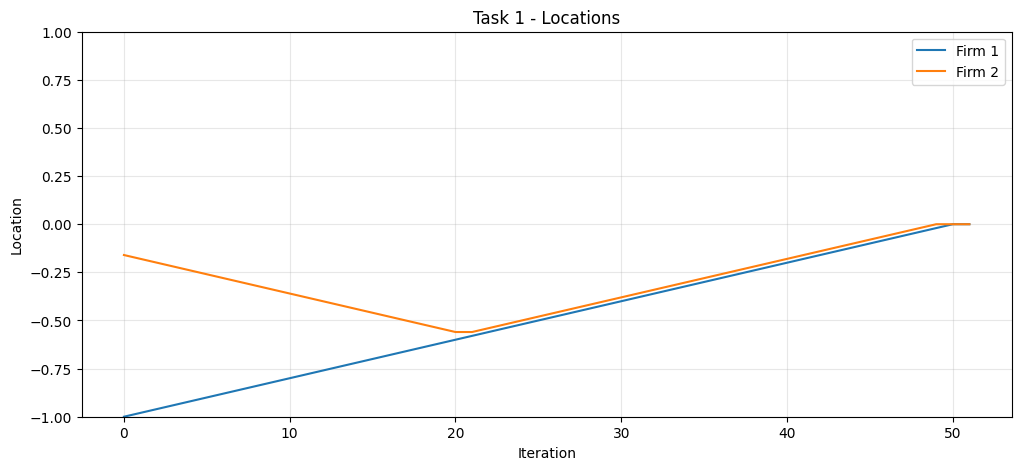

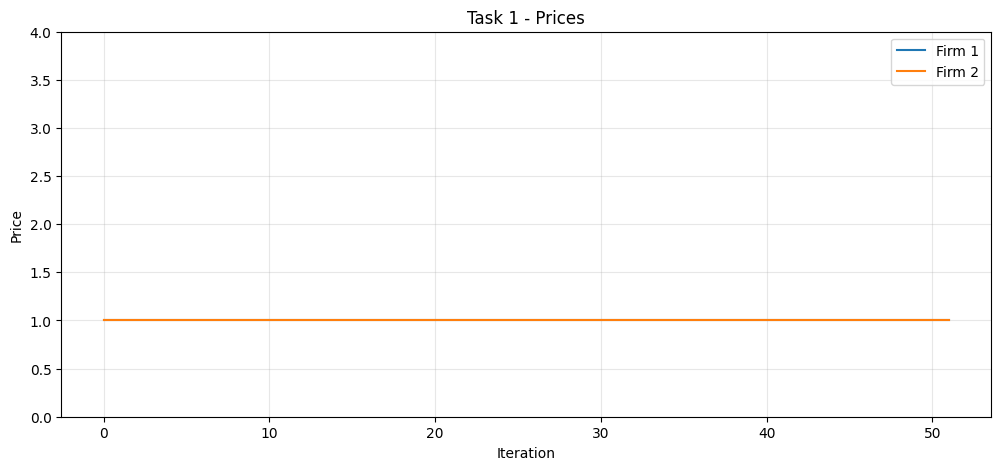

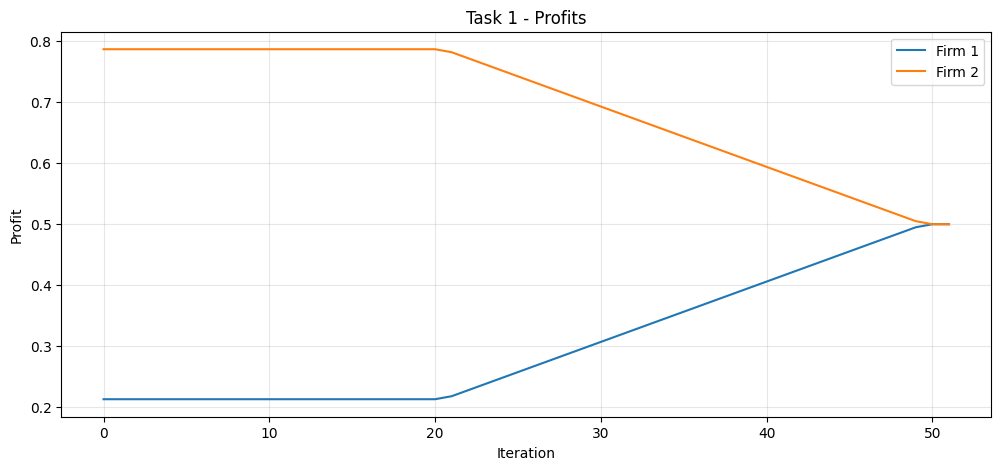

Task 1
Stop reason: Convergence
First cycle iteration: None
Cycle length: None
Number of iterations: 51


In [39]:
plot_results(
    history_x_1,
    history_p_1,
    history_profit_1,
    stop_reason_1,
    first_iteration_1,
    cycle_length_1,
    1
)

In [40]:
history_p_3

[array([2.8, 1.9]),
 array([2.7, 2. ]),
 array([2.6, 2.1]),
 array([2.5, 2.2]),
 array([2.4, 2.3]),
 array([2.4, 2.4]),
 array([2.5, 2.5]),
 array([2.5, 2.6]),
 array([2.6, 2.7]),
 array([2.6, 2.8]),
 array([2.7, 2.9]),
 array([2.7, 3. ]),
 array([2.8, 3.1]),
 array([2.8, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.9, 3.2]),
 array([2.8, 3.1]),
 array([2.7, 3. ]),
 array([2.6, 2.9]),
 array([2.5, 2.8]),
 array([2.4, 2.7]),
 array([2.3, 2.6]),
 array([2.2, 2.5]),
 array([2.1, 2.4]),
 array([2. , 2.3]),
 array([1.9, 2.2]),
 array([1.8, 2.1]),
 array([1.7, 2. ]),
 array([1.6, 1.9]),
 array([1.5, 1.8]),
 array([1.4, 1.7]),
 array([1.3, 1.6]),
 array([1.2, 1.5]),
 array([1.1, 1.4]),
 array([1.2, 1.5]),
 array([1.2, 1.5]),
 array([1.2, 1.5]),
 array([1.2, 1.5]),


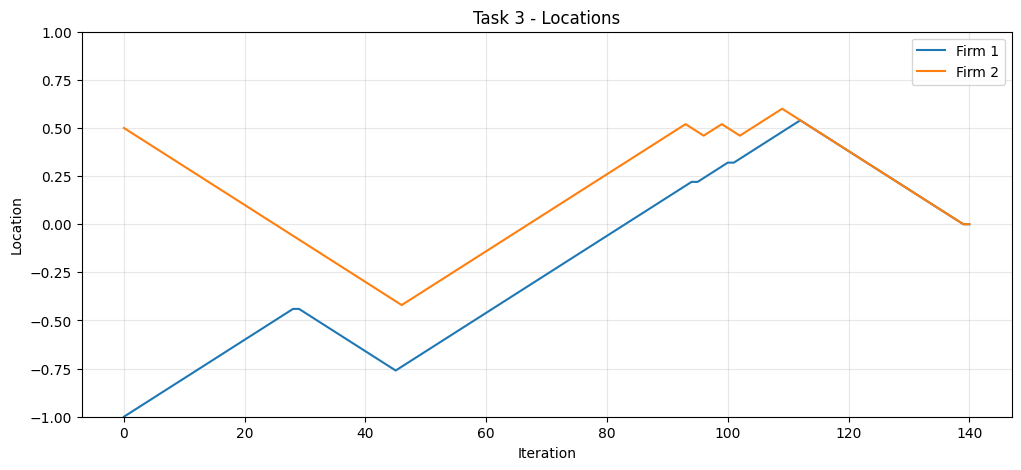

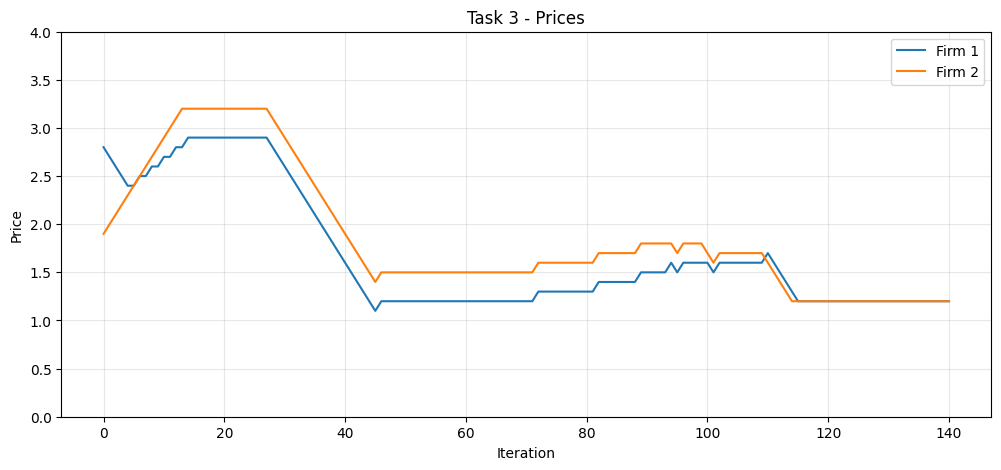

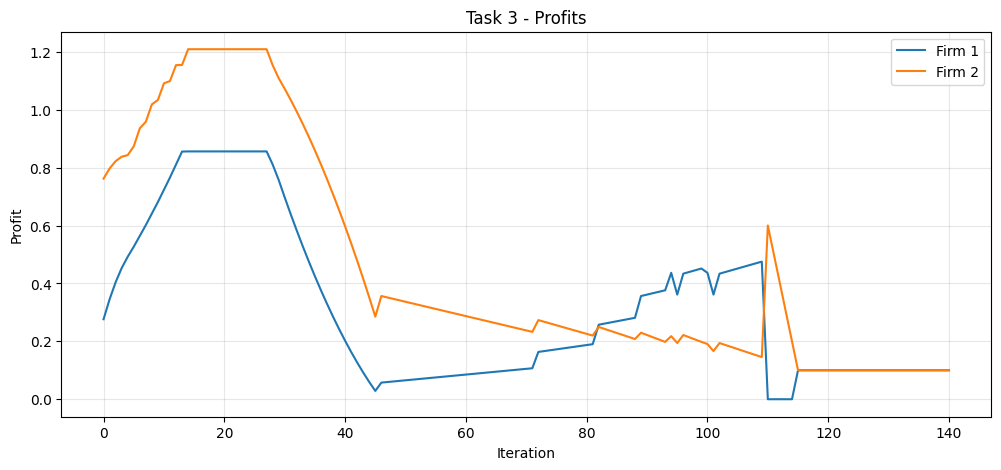

Task 3
Stop reason: Convergence
First cycle iteration: None
Cycle length: None
Number of iterations: 140


In [41]:
plot_results(
    history_x_3,
    history_p_3,
    history_profit_3,
    stop_reason_3,
    first_iteration_3,
    cycle_length_3,
    3
)

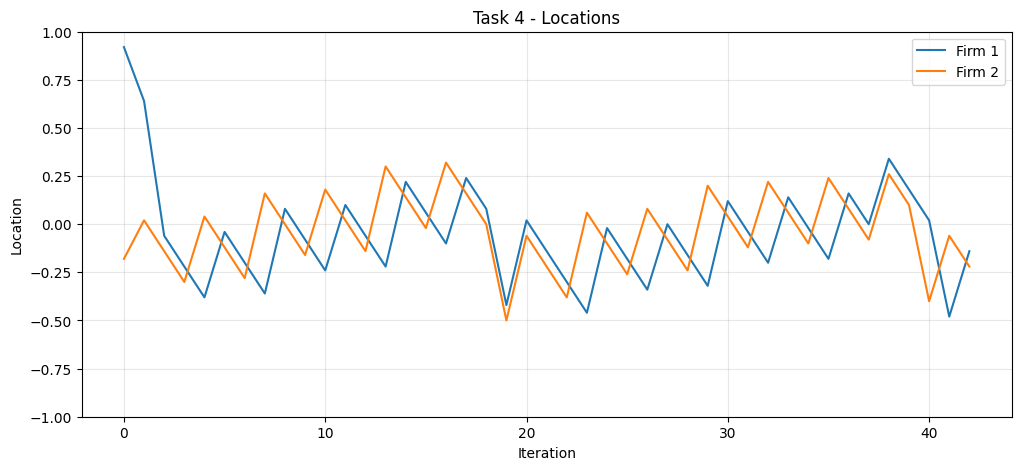

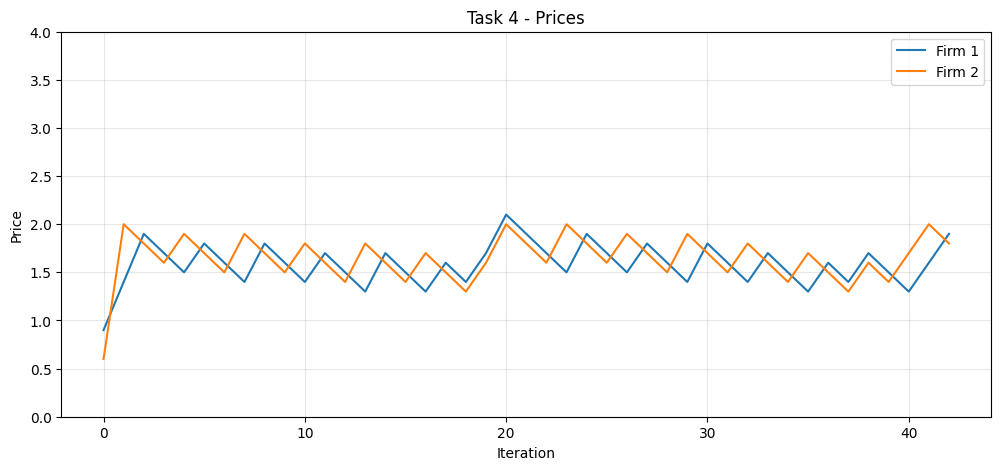

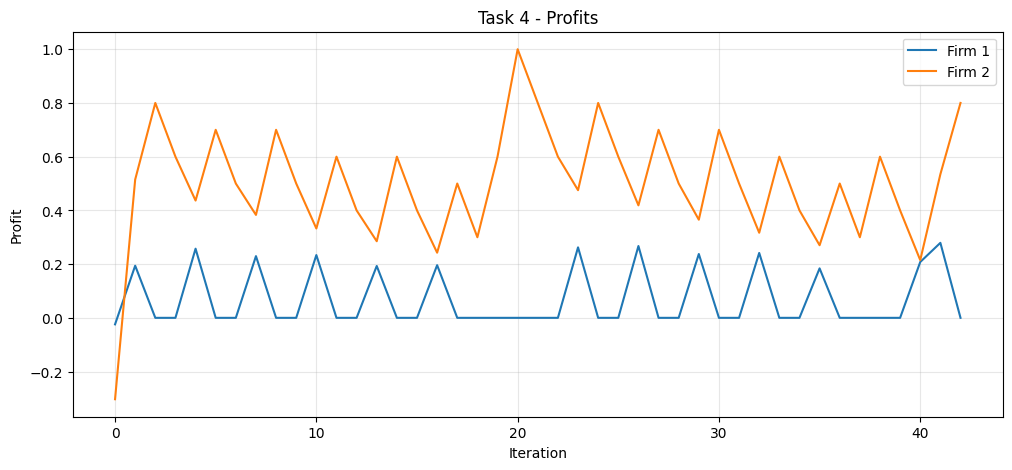

Task 4
Stop reason: Cycle
First cycle iteration: 21
Cycle length: 21
Number of iterations: 42


In [42]:
plot_results(
    history_x_4,
    history_p_4,
    history_profit_4,
    stop_reason_4,
    first_iteration_4,
    cycle_length_4,
    4
)

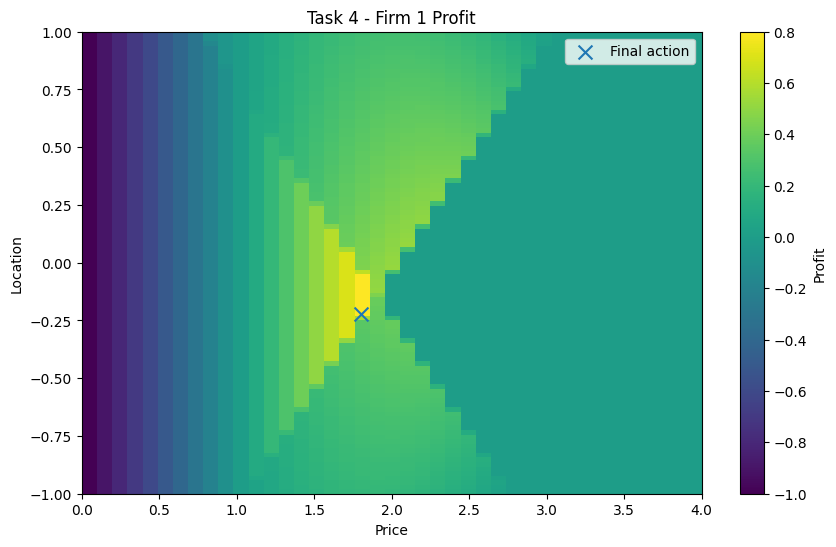

In [43]:
# Task 4 - Profit heatmap for Firm 1

firm = 1

profit_matrix = np.zeros(
    (len(road), len(prices))
)

for i, pos in enumerate(road):

    for j, price in enumerate(prices):

        # Copy final state
        x_new = x_4.copy()
        p_new = p_4.copy()

        # Change only Firm 1
        x_new[firm] = pos
        p_new[firm] = price

        # Profit of Firm 1
        profit_matrix[i, j] = calculate_profit(
            x_new,
            p_new,
            costfunc1D, k, c0, demandfunc1, e
        )[firm]


plt.figure(figsize=(10, 6))

plt.imshow(
    profit_matrix,
    origin="lower",
    aspect="auto",
    extent=[
        prices[0],
        prices[-1],
        road[0],
        road[-1]
    ]
)

plt.colorbar(label="Profit")

plt.xlabel("Price")
plt.ylabel("Location")
plt.title("Task 4 - Firm 1 Profit")

plt.scatter(
    p_4[firm],
    x_4[firm],
    marker="x",
    s=100,
    label="Final action"
)

plt.legend()
plt.show()

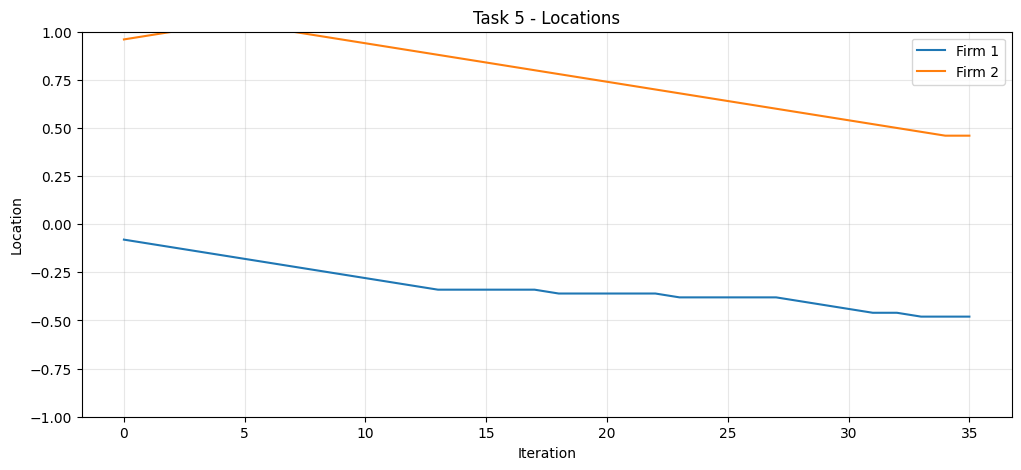

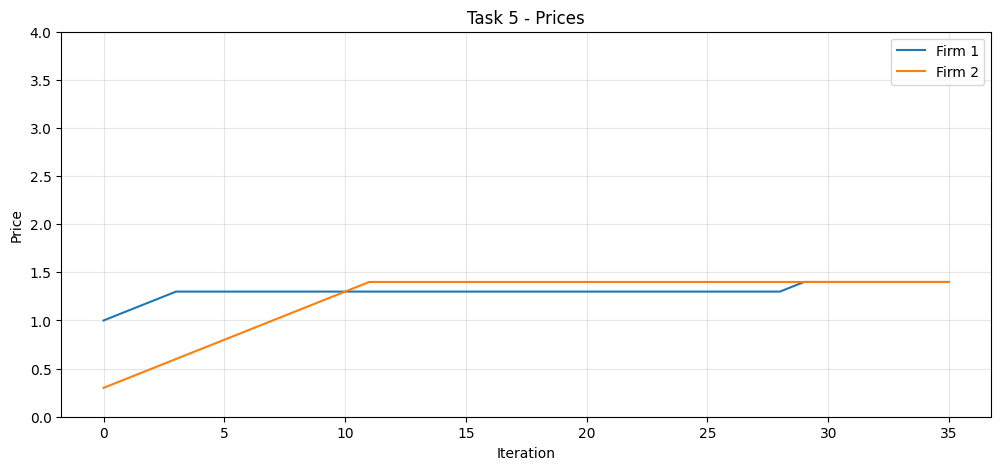

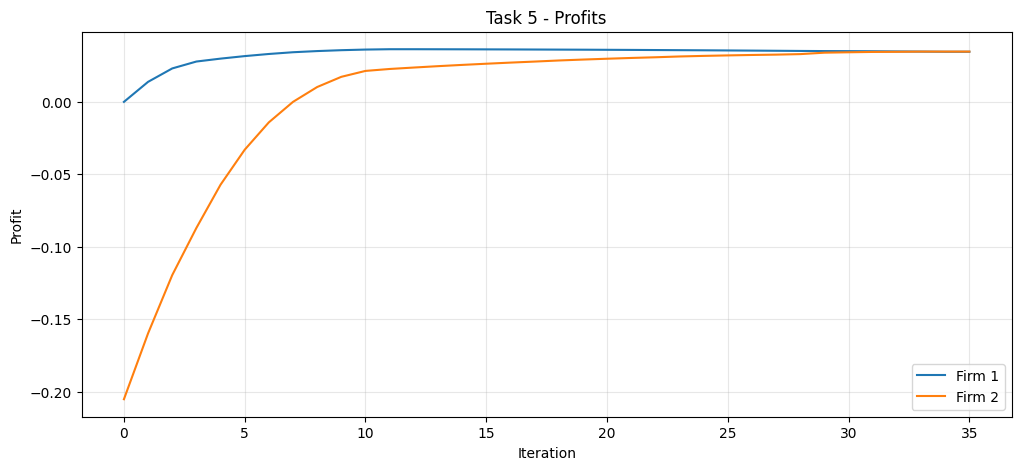

Task 5
Stop reason: Convergence
First cycle iteration: None
Cycle length: None
Number of iterations: 35


In [44]:
plot_results(
    history_x_5,
    history_p_5,
    history_profit_5,
    stop_reason_5,
    first_iteration_5,
    cycle_length_5,
    5
)

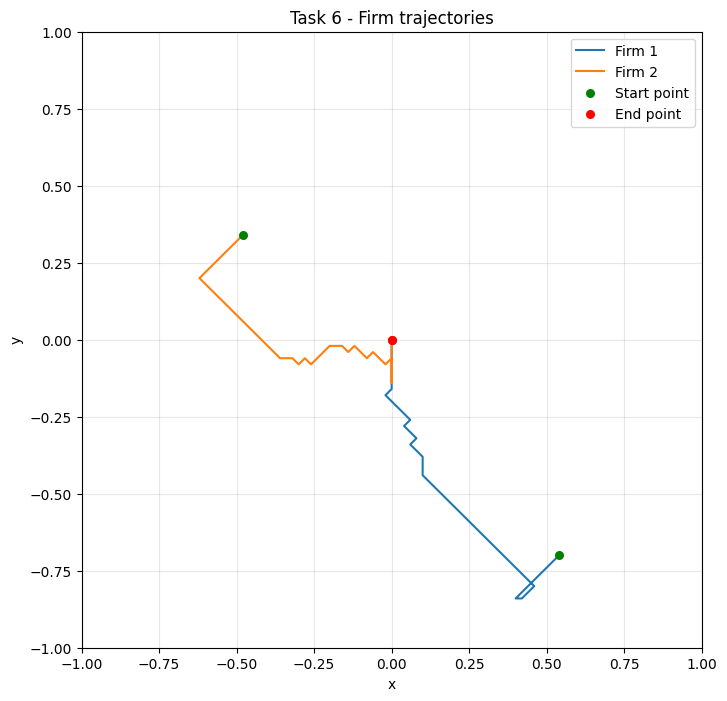

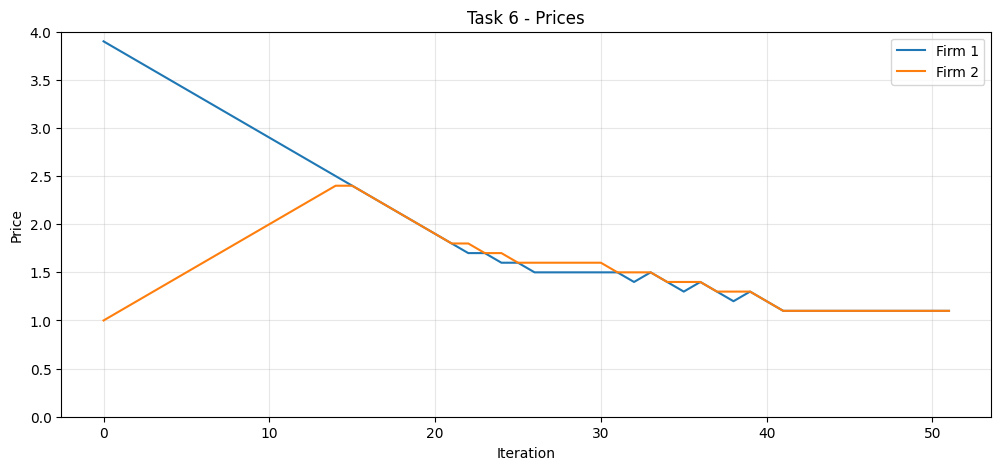

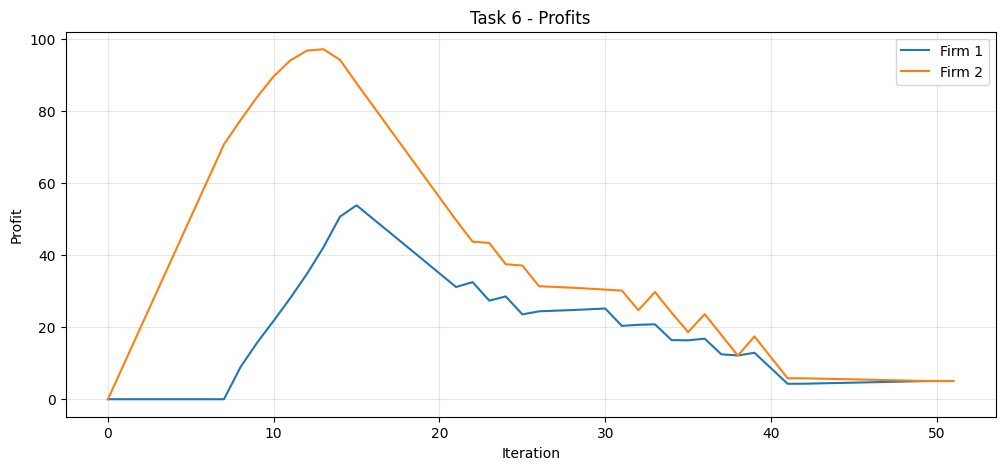

Task 6
Stop reason: Convergence
First cycle iteration: None
Cycle length: None
Number of iterations: 51


In [45]:
plot_results(
    history_x_6,
    history_p_6,
    history_profit_6,
    stop_reason_6,
    first_iteration_6,
    cycle_length_6,
    6
)

In [46]:
#plot_results(
#    history_x_4,
#    history_p_4,
#    stop_reason_4,
#    first_iteration_4,
#    cycle_length_4,
#    4
#)

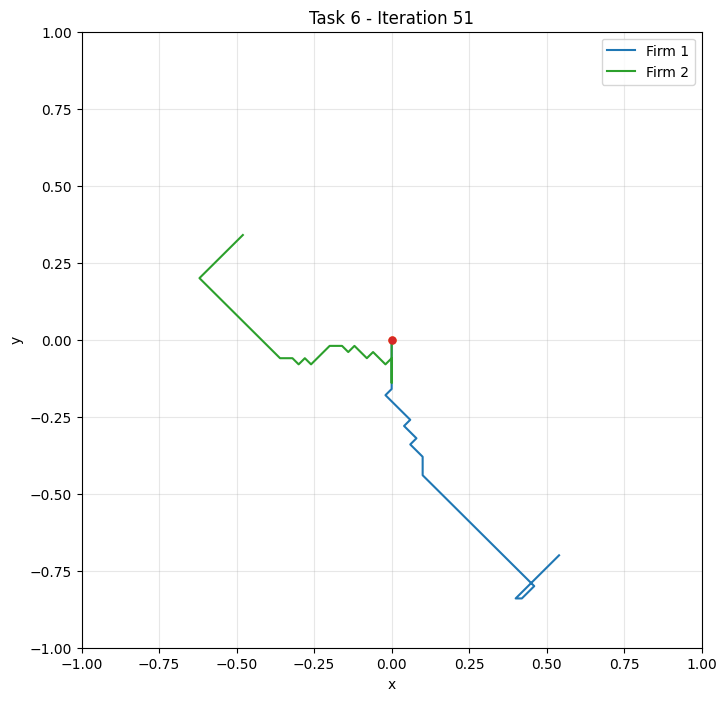

In [47]:
from matplotlib.animation import FuncAnimation, PillowWriter

history = np.array(history_x_6)

start = 0
end = len(history)

fig, ax = plt.subplots(figsize=(8, 8))

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Task 6 - Firm movement")
ax.grid(alpha=0.3)

m = history.shape[1]

lines = []
dots = []

for firm in range(m):
    line, = ax.plot([], [], label=f"Firm {firm + 1}")
    dot, = ax.plot([], [], marker="o", markersize=5)

    lines.append(line)
    dots.append(dot)

ax.legend()


def update(frame):

    for firm in range(m):

        # Path up to current frame
        lines[firm].set_data(
            history[start:frame + 1, firm, 0],
            history[start:frame + 1, firm, 1]
        )

        # Current position
        dots[firm].set_data(
            [history[frame, firm, 0]],
            [history[frame, firm, 1]]
        )

    ax.set_title(f"Task 6 - Iteration {frame}")

    return lines + dots


animation = FuncAnimation(
    fig,
    update,
    frames=range(start, end),
    interval=100,
    blit=False
)

animation.save(
    "task6_trajectories_m10.gif",
    writer=PillowWriter(fps=10)
)

plt.show()